# Hysteresis by time-stepping continuation (Pe = 6, φ = 0.905 and 0.915)

In [10]:
include("../src/hysteresis.jl")

# true: compute that data again and save it in data/hysteresis; false: load the saved data
# (chains: several hours, every run saved in full in data/hysteresis/runs; videos: about five minutes)
COMPUTE = (chains=false, videos=false)

(chains = false, videos = false)

## Continuation chains and their recordings

In [11]:
# Chains along φa (the decreasing one first: the increasing one is staggered with respect to it), and each chain as one
# continuous run: the saved histories of its accepted runs joined in order
chains = Dict()
for ϕ in PHIS_H
    chains[(ϕ, "down")] = getdata(() -> hysteresis_chain(ϕ, "down"), "hysteresis/chain_down_phi$(ϕ).jld2", COMPUTE.chains)
    chains[(ϕ, "up")] = getdata(() -> hysteresis_chain(ϕ, "up"; down=chains[(ϕ, "down")]), "hysteresis/chain_up_phi$(ϕ).jld2", COMPUTE.chains)
end
recs = Dict(ϕ => [chain_record(ϕ, d, chains[(ϕ, d)]) for d in ("up", "down")] for ϕ in PHIS_H);

## Figure

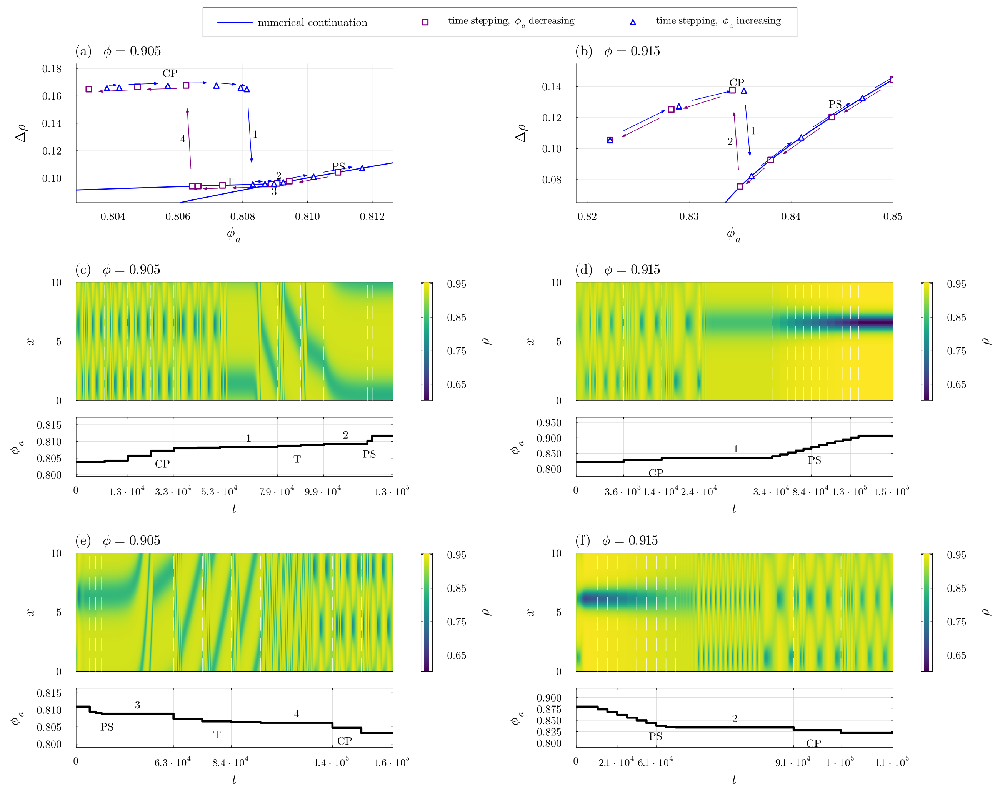

In [12]:
# Δρ diagrams with the Newton branches of the oscillatory notebook (data/oscillatory) and both chains, and the kymographs
diagrams = Dict(ϕ => (tb = loaddata("oscillatory/travelling_phi$(ϕ).jld2");
                      (tb, ps_branches(ϕ, tb, false), chains[(ϕ, "down")], chains[(ϕ, "up")])) for ϕ in PHIS_H)
savepdf(hysteresis_figure(diagrams, recs), "hysteresis_kymograph")

## Videos

In [13]:
if COMPUTE.videos
    for ϕ in PHIS_H, d in ("up", "down")
        hysteresis_video(ϕ, d, recs[ϕ])
    end
end
show_video(video_name(0.905, "up"))

HTML{String}("<video controls loop style=\"width:100%; max-width:900px; height:auto\" src=\"

In [14]:
show_video(video_name(0.905, "down"))

HTML{String}("<video controls loop style=\"width:100%; max-width:900px; height:auto\" src=\"

In [15]:
show_video(video_name(0.915, "up"))

HTML{String}("<video controls loop style=\"width:100%; max-width:900px; height:auto\" src=\"

In [16]:
show_video(video_name(0.915, "down"))

HTML{String}("<video controls loop style=\"width:100%; max-width:900px; height:auto\" src=\"